In [2]:
import os, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
warnings.filterwarnings("ignore")

os.makedirs("data", exist_ok=True)
can = ["khach_vay.csv", "gia_nha.csv"]
thieu = [f for f in can if not os.path.exists(f"data/{f}")]
if thieu:
    # Colab: hộp thoại chọn tệp. Hãy chọn khach_vay.csv và gia_nha.csv
    from google.colab import files
    print("Hay tai len:", thieu)
    up = files.upload()
    for ten, noi_dung in up.items():
        with open(f"data/{ten}", "wb") as f:
            f.write(noi_dung)
print(os.listdir("data"))

Hay tai len: ['khach_vay.csv', 'gia_nha.csv']


Saving gia_nha.csv to gia_nha.csv
Saving khach_vay.csv to khach_vay.csv
['gia_nha.csv', 'khach_vay.csv']


## 2. Tự tính chỉ số Gini (f1_gini.py)

In [3]:
from sklearn.tree import DecisionTreeClassifier, export_text

# Mười khách vay để tính tay
nho = pd.DataFrame({
    "thu_nhap":        [6, 8, 9, 11, 13, 15, 18, 20, 25, 30],
    "co_viec_on_dinh": [0, 0, 0, 1, 1, 1, 1, 1, 1, 1],
    "tra_dung_han":    [0, 1, 0, 0, 1, 1, 0, 1, 1, 1],
})
y = nho["tra_dung_han"].to_numpy()

def gini(nhan):
    """Chi so Gini cua mot nut co hai lop."""
    if len(nhan) == 0:
        return 0.0
    p1 = nhan.mean()
    return 1 - p1 ** 2 - (1 - p1) ** 2

def gini_sau_chia(di_trai):
    """Gini trung binh co trong so cua hai nhanh."""
    trai, phai = y[di_trai], y[~di_trai]
    n = len(y)
    return len(trai) / n * gini(trai) + len(phai) / n * gini(phai)

g_goc = gini(y)
print(f"Gini cua nut goc: {g_goc:.4f}\n")

thu = nho["thu_nhap"].to_numpy()
muc = np.sort(np.unique(thu))
print("Cau hoi 'thu_nhap <= nguong ?'")
print("  nguong  Gini sau chia  Gini giam")
for a, b in zip(muc[:-1], muc[1:]):
    nguong = (a + b) / 2
    g = gini_sau_chia(thu <= nguong)
    print(f"  {nguong:6.1f}  {g:13.4f}  {g_goc - g:9.4f}")
print()

viec = nho["co_viec_on_dinh"].to_numpy()
g_viec = gini_sau_chia(viec == 0)
print("Cau hoi 'co viec on dinh ?'")
print(f"  Gini sau chia {g_viec:.4f}, Gini giam {g_goc - g_viec:.4f}\n")

cot = ["thu_nhap", "co_viec_on_dinh"]
cay = DecisionTreeClassifier(max_depth=1, random_state=0)
cay.fit(nho[cot], y)
print("Cay mot tang do scikit-learn chon:")
print(export_text(cay, feature_names=cot, show_weights=True))

Gini cua nut goc: 0.4800

Cau hoi 'thu_nhap <= nguong ?'
  nguong  Gini sau chia  Gini giam
     7.0         0.4000     0.0800
     8.5         0.4750     0.0050
    10.0         0.4190     0.0610
    12.0         0.3167     0.1633
    14.0         0.4000     0.0800
    16.5         0.4500     0.0300
    19.0         0.3429     0.1371
    22.5         0.4000     0.0800
    27.5         0.4444     0.0356

Cau hoi 'co viec on dinh ?'
  Gini sau chia 0.4190, Gini giam 0.0610

Cay mot tang do scikit-learn chon:
|--- thu_nhap <= 12.00
|   |--- weights: [3.00, 1.00] class: 0
|--- thu_nhap >  12.00
|   |--- weights: [1.00, 5.00] class: 1



## 3. Cây đầu tiên trên dữ liệu khách vay (f2_cay_nam_la.py)

In [6]:
from sklearn.metrics import accuracy_score
from sklearn.model_selection import train_test_split
from sklearn.tree import plot_tree

df = pd.read_csv("data/khach_vay.csv")
print("Kich thuoc bang:", df.shape)
print(df.head())
print("\nTy le khach tra dung han:", round(df["tra_dung_han"].mean(), 2), "\n")

X = df.drop(columns="tra_dung_han")
y = df["tra_dung_han"]
X_tr, X_te, y_tr, y_te = train_test_split(
    X, y, test_size=0.25, random_state=17, stratify=y
)

cay = DecisionTreeClassifier(max_leaf_nodes=5, random_state=0)
cay.fit(X_tr, y_tr)

print(f"Do sau {cay.get_depth()}, so la {cay.get_n_leaves()}")
print(export_text(cay, feature_names=list(X.columns), show_weights=True, decimals=3))

a_hoc = accuracy_score(y_tr, cay.predict(X_tr))
a_kt = accuracy_score(y_te, cay.predict(X_te))
print(f"Accuracy tap hoc      : {a_hoc:.4f}")
print(f"Accuracy tap kiem tra : {a_kt:.4f}\n")

moi = pd.DataFrame({
    "thu_nhap": [20.0, 10.0],
    "ty_le_no": [0.4, 0.3],
    "co_viec_on_dinh": [1, 0],
    "so_nguoi_phu_thuoc": [2, 1],
})
du_doan = cay.predict(moi)
xac_suat = cay.predict_proba(moi)[:, 1]
for i in range(len(moi)):
    ket = "dung han" if du_doan[i] == 1 else "tre han"
    print(f"Khach {i + 1}: {ket}, xac suat dung han {xac_suat[i]:.2f}")

Kich thuoc bang: (600, 5)
   thu_nhap  ty_le_no  co_viec_on_dinh  so_nguoi_phu_thuoc  tra_dung_han
0       9.4      0.18                0                   4             0
1      15.8      0.70                0                   2             1
2       6.1      0.79                0                   0             0
3      19.4      1.13                1                   4             0
4      24.8      0.33                1                   0             1

Ty le khach tra dung han: 0.49 

Do sau 3, so la 5
|--- thu_nhap <= 15.050
|   |--- ty_le_no <= 0.615
|   |   |--- co_viec_on_dinh <= 0.500
|   |   |   |--- weights: [33.000, 6.000] class: 0
|   |   |--- co_viec_on_dinh >  0.500
|   |   |   |--- weights: [35.000, 47.000] class: 1
|   |--- ty_le_no >  0.615
|   |   |--- weights: [114.000, 14.000] class: 0
|--- thu_nhap >  15.050
|   |--- ty_le_no <= 1.020
|   |   |--- weights: [27.000, 145.000] class: 1
|   |--- ty_le_no >  1.020
|   |   |--- weights: [20.000, 9.000] class: 0

Acc

## 4. Cây học vẹt và cách chọn độ sâu (f3_do_sau.py)

Cay moc tu do
  do sau 13, so la 92
  tap hoc 1.0000, tap kiem tra 0.7667

Do sau  tap hoc  kiem dinh cheo
   1    0.7467    0.7244
   2    0.7711    0.7378
   3    0.8000    0.7511
   4    0.8644    0.8089
   5    0.8978    0.8333
   6    0.9133    0.8156
   7    0.9400    0.8067
   8    0.9600    0.7733
   9    0.9800    0.7800
  10    0.9911    0.7822
  11    0.9933    0.7756
  12    0.9978    0.7778
  13    1.0000    0.7733
  14    1.0000    0.7733
  15    1.0000    0.7733

Do sau tot nhat = 5, cay co 27 la
Accuracy tren tap kiem tra = 0.8533


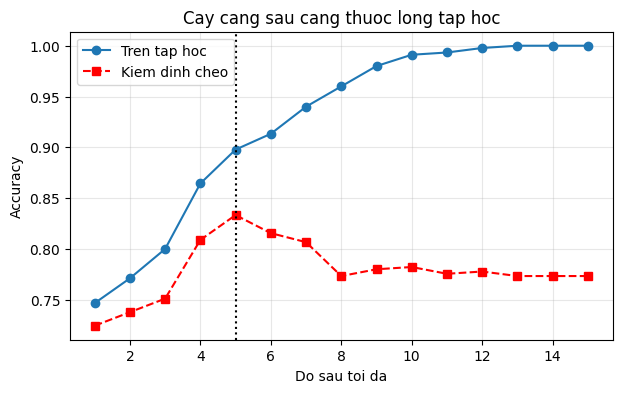

In [7]:
from sklearn.model_selection import cross_val_score

tu_do = DecisionTreeClassifier(random_state=0).fit(X_tr, y_tr)
print("Cay moc tu do")
print(f"  do sau {tu_do.get_depth()}, so la {tu_do.get_n_leaves()}")
a_hoc = accuracy_score(y_tr, tu_do.predict(X_tr))
a_kt = accuracy_score(y_te, tu_do.predict(X_te))
print(f"  tap hoc {a_hoc:.4f}, tap kiem tra {a_kt:.4f}\n")

print("Do sau  tap hoc  kiem dinh cheo")
diem, hoc_list = {}, {}
for d in range(1, 16):
    mh = DecisionTreeClassifier(max_depth=d, random_state=0)
    diem[d] = cross_val_score(mh, X_tr, y_tr, cv=5).mean()
    hoc_list[d] = accuracy_score(y_tr, mh.fit(X_tr, y_tr).predict(X_tr))
    print(f"  {d:2d}    {hoc_list[d]:.4f}    {diem[d]:.4f}")
d_tot = max(diem, key=diem.get)
print()

tot = DecisionTreeClassifier(max_depth=d_tot, random_state=0).fit(X_tr, y_tr)
print(f"Do sau tot nhat = {d_tot}, cay co {tot.get_n_leaves()} la")
acc_depth5 = accuracy_score(y_te, tot.predict(X_te))
print(f"Accuracy tren tap kiem tra = {acc_depth5:.4f}")

# Hinh 4
plt.figure(figsize=(7, 4))
plt.plot(list(hoc_list), list(hoc_list.values()), "o-", label="Tren tap hoc")
plt.plot(list(diem), list(diem.values()), "s--", color="red", label="Kiem dinh cheo")
plt.axvline(d_tot, ls=":", color="k")
plt.xlabel("Do sau toi da"); plt.ylabel("Accuracy")
plt.title("Cay cang sau cang thuoc long tap hoc"); plt.legend(); plt.grid(alpha=.3)
plt.show()

## 5. Cây không cần chuẩn hoá (f4_khong_chuan_hoa.py)

In [8]:
from sklearn.preprocessing import StandardScaler

def cay_sau_5():
    return DecisionTreeClassifier(max_depth=5, random_state=0)

goc = cay_sau_5().fit(X_tr, y_tr)
du_goc = goc.predict(X_te)

sc = StandardScaler().fit(X_tr)
chuan = cay_sau_5().fit(sc.transform(X_tr), y_tr)
du_chuan = chuan.predict(sc.transform(X_te))

X_tr_n, X_te_n = X_tr.copy(), X_te.copy()
X_tr_n["thu_nhap"] = X_tr_n["thu_nhap"] * 1000
X_te_n["thu_nhap"] = X_te_n["thu_nhap"] * 1000
nghin = cay_sau_5().fit(X_tr_n, y_tr)
du_nghin = nghin.predict(X_te_n)

print("Accuracy tren tap kiem tra")
print(f"  du lieu goc         : {accuracy_score(y_te, du_goc):.4f}")
print(f"  da chuan hoa        : {accuracy_score(y_te, du_chuan):.4f}")
print(f"  thu nhap nghin dong : {accuracy_score(y_te, du_nghin):.4f}\n")
print("So khach bi doan khac cay goc")
print(f"  da chuan hoa        : {(du_chuan != du_goc).sum()}")
print(f"  thu nhap nghin dong : {(du_nghin != du_goc).sum()}\n")
print("Nguong cua cau hoi goc")
print(f"  du lieu goc         : {goc.tree_.threshold[0]:.2f}")
print(f"  thu nhap nghin dong : {nghin.tree_.threshold[0]:.2f}")

Accuracy tren tap kiem tra
  du lieu goc         : 0.8533
  da chuan hoa        : 0.8533
  thu nhap nghin dong : 0.8533

So khach bi doan khac cay goc
  da chuan hoa        : 0
  thu nhap nghin dong : 0

Nguong cua cau hoi goc
  du lieu goc         : 15.05
  thu nhap nghin dong : 15050.00


## 6. Rừng ngẫu nhiên (f5_rung.py)

In [9]:
from sklearn.ensemble import RandomForestClassifier

rng = np.random.default_rng(0)
n = len(X_tr)
chi_so = rng.integers(0, n, n)
khac = len(np.unique(chi_so))
print(f"Boc {n} lan, co {khac} khach khac nhau ({khac / n:.0%})\n")

rung = RandomForestClassifier(n_estimators=200, random_state=0)
rung.fit(X_tr, y_tr)
print("Rung 200 cay")
print(f"  tap hoc      : {accuracy_score(y_tr, rung.predict(X_tr)):.4f}")
print(f"  tap kiem tra : {accuracy_score(y_te, rung.predict(X_te)):.4f}\n")

print("So cay  accuracy tap kiem tra")
for m in [1, 10, 50, 200, 400]:
    r = RandomForestClassifier(n_estimators=m, random_state=0)
    r.fit(X_tr, y_tr)
    print(f"  {m:4d}   {accuracy_score(y_te, r.predict(X_te)):.4f}")
print()

ba_mo_hinh = {
    "Cay moc tu do": DecisionTreeClassifier(random_state=0),
    "Cay sau 5": DecisionTreeClassifier(max_depth=5, random_state=0),
    "Rung 200 cay": rung,
}
print("Mo hinh          tap hoc  tap kiem tra")
for ten, mh in ba_mo_hinh.items():
    mh.fit(X_tr, y_tr)
    a = accuracy_score(y_tr, mh.predict(X_tr))
    b = accuracy_score(y_te, mh.predict(X_te))
    print(f"  {ten:14s} {a:.4f}   {b:.4f}")

Boc 450 lan, co 286 khach khac nhau (64%)

Rung 200 cay
  tap hoc      : 1.0000
  tap kiem tra : 0.9000

So cay  accuracy tap kiem tra
     1   0.7933
    10   0.8467
    50   0.8733
   200   0.9000
   400   0.9000

Mo hinh          tap hoc  tap kiem tra
  Cay moc tu do  1.0000   0.7667
  Cay sau 5      0.8978   0.8533
  Rung 200 cay   1.0000   0.9000


## 7. Độ quan trọng của đặc trưng (f6_do_quan_trong.py)

In [10]:
rung = RandomForestClassifier(n_estimators=200, random_state=0)
rung.fit(X_tr, y_tr)
qt = pd.Series(rung.feature_importances_, index=X.columns)
print("Do quan trong, bon cot that")
print(qt.sort_values(ascending=False).round(3).to_string())
print("Tong:", round(qt.sum(), 3), "\n")

rng = np.random.default_rng(0)
X_tr_nn = X_tr.copy()
X_tr_nn["so_ngau_nhien"] = rng.random(len(X_tr))
rung_nn = RandomForestClassifier(n_estimators=200, random_state=0)
rung_nn.fit(X_tr_nn, y_tr)
qt_nn = pd.Series(rung_nn.feature_importances_, index=X_tr_nn.columns)
print("Do quan trong, them mot cot ngau nhien")
print(qt_nn.sort_values(ascending=False).round(3).to_string())

Do quan trong, bon cot that
thu_nhap              0.479
ty_le_no              0.339
so_nguoi_phu_thuoc    0.093
co_viec_on_dinh       0.088
Tong: 1.0 

Do quan trong, them mot cot ngau nhien
thu_nhap              0.427
ty_le_no              0.270
so_ngau_nhien         0.150
co_viec_on_dinh       0.077
so_nguoi_phu_thuoc    0.076


## 8. Cây cho bài toán hồi quy (f7_cay_hoi_quy.py)

Cay hoi quy sau 3 co 8 la
|--- dien_tich <= 73.9
|   |--- dien_tich <= 64.7
|   |   |--- dien_tich <= 50.5
|   |   |   |--- value: [4.2]
|   |   |--- dien_tich >  50.5
|   |   |   |--- value: [4.9]
|   |--- dien_tich >  64.7
|   |   |--- dien_tich <= 68.5
|   |   |   |--- value: [5.3]
|   |   |--- dien_tich >  68.5
|   |   |   |--- value: [5.9]
|--- dien_tich >  73.9
|   |--- dien_tich <= 93.8
|   |   |--- dien_tich <= 82.5
|   |   |   |--- value: [6.8]
|   |   |--- dien_tich >  82.5
|   |   |   |--- value: [7.4]
|   |--- dien_tich >  93.8
|   |   |--- dien_tich <= 107.7
|   |   |   |--- value: [8.3]
|   |   |--- dien_tich >  107.7
|   |   |   |--- value: [9.4]

MAE tren tap kiem tra (ty dong)
  Cay sau 3  : 0.5039
  Duong thang: 0.2578

Du doan cho bon can moi (ty dong)
  dien tich    cay   duong thang
      60 m2    4.92    5.12
     100 m2    8.32    8.24
     150 m2    9.40   12.13
     250 m2    9.40   19.91


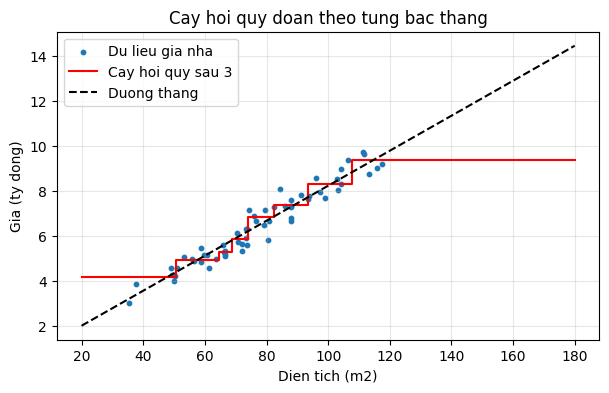

In [11]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error
from sklearn.tree import DecisionTreeRegressor

dfn = pd.read_csv("data/gia_nha.csv")
Xn = dfn[["dien_tich"]]
yn = dfn["gia"]
Xn_tr, Xn_te, yn_tr, yn_te = train_test_split(Xn, yn, test_size=0.2, random_state=42)

cay_hq = DecisionTreeRegressor(max_depth=3, random_state=0).fit(Xn_tr, yn_tr)
duong = LinearRegression().fit(Xn_tr, yn_tr)

print(f"Cay hoi quy sau 3 co {cay_hq.get_n_leaves()} la")
print(export_text(cay_hq, feature_names=["dien_tich"], decimals=1))

mae_cay = mean_absolute_error(yn_te, cay_hq.predict(Xn_te))
mae_duong = mean_absolute_error(yn_te, duong.predict(Xn_te))
print("MAE tren tap kiem tra (ty dong)")
print(f"  Cay sau 3  : {mae_cay:.4f}")
print(f"  Duong thang: {mae_duong:.4f}\n")

can_moi = pd.DataFrame({"dien_tich": [60.0, 100.0, 150.0, 250.0]})
print("Du doan cho bon can moi (ty dong)")
print("  dien tich    cay   duong thang")
for dt, a, b in zip(can_moi["dien_tich"], cay_hq.predict(can_moi), duong.predict(can_moi)):
    print(f"  {dt:6.0f} m2  {a:6.2f}  {b:6.2f}")

# Hinh 8
xs = pd.DataFrame({"dien_tich": np.linspace(20, 180, 400)})
plt.figure(figsize=(7, 4))
plt.scatter(Xn["dien_tich"], yn, s=10, label="Du lieu gia nha")
plt.step(xs["dien_tich"], cay_hq.predict(xs), color="red", where="mid", label="Cay hoi quy sau 3")
plt.plot(xs["dien_tich"], duong.predict(xs), "k--", label="Duong thang")
plt.xlabel("Dien tich (m2)"); plt.ylabel("Gia (ty dong)")
plt.legend(); plt.grid(alpha=.3); plt.title("Cay hoi quy doan theo tung bac thang")
plt.show()

## 9. Bài tập

### Bài tập 1: Tự vẽ cây

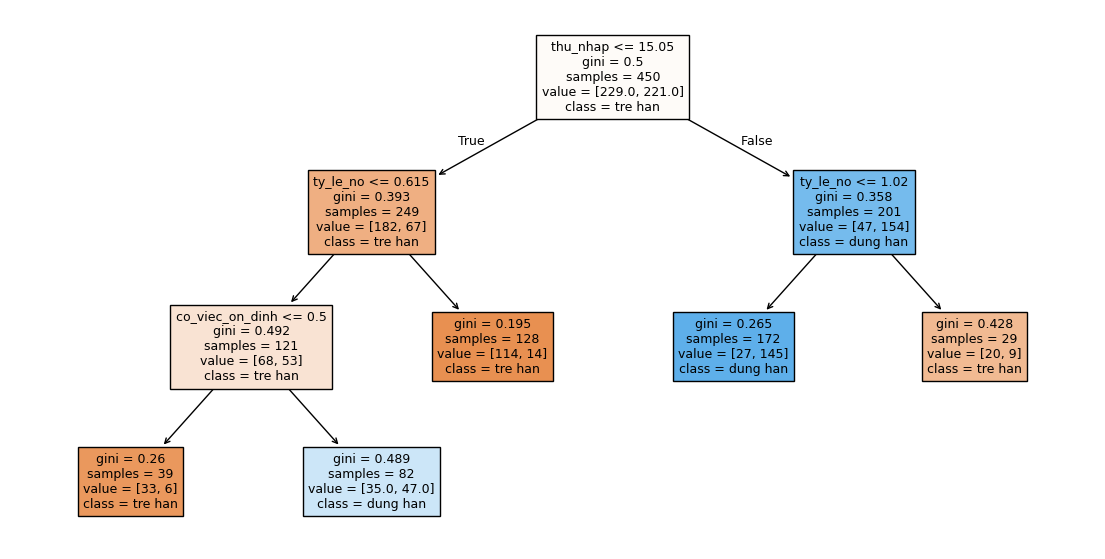

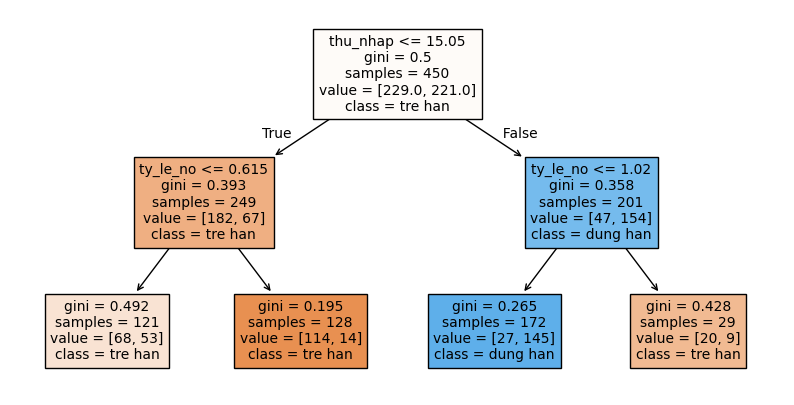

|--- thu_nhap <= 15.050
|   |--- ty_le_no <= 0.615
|   |   |--- weights: [68.000, 53.000] class: 0
|   |--- ty_le_no >  0.615
|   |   |--- weights: [114.000, 14.000] class: 0
|--- thu_nhap >  15.050
|   |--- ty_le_no <= 1.020
|   |   |--- weights: [27.000, 145.000] class: 1
|   |--- ty_le_no >  1.020
|   |   |--- weights: [20.000, 9.000] class: 0

La 2: value=[0.56198347 0.43801653], gini=0.492, ket luan = tre han
La 3: value=[0.890625 0.109375], gini=0.195, ket luan = tre han


In [12]:
# Cay nam la o muc 3
cay5 = DecisionTreeClassifier(max_leaf_nodes=5, random_state=0).fit(X_tr, y_tr)
plt.figure(figsize=(14, 7))
plot_tree(cay5, feature_names=list(X.columns), class_names=["tre han", "dung han"],
          filled=True, rounded=False, fontsize=9)
plt.savefig("cay_nam_la.png", dpi=150, bbox_inches="tight")
plt.show()

# Cay sau 2
cay2 = DecisionTreeClassifier(max_depth=2, random_state=0).fit(X_tr, y_tr)
plt.figure(figsize=(10, 5))
plot_tree(cay2, feature_names=list(X.columns), class_names=["tre han", "dung han"],
          filled=True, fontsize=10)
plt.savefig("cay_sau_2.png", dpi=150, bbox_inches="tight")
plt.show()
print(export_text(cay2, feature_names=list(X.columns), show_weights=True, decimals=3))

# Kiem tra hai la ben trai co cung ket luan khong
t = cay2.tree_
la_trai = t.children_left[t.children_left[0]], t.children_right[t.children_left[0]]
for i in la_trai:
    v = t.value[i][0]
    print(f"La {i}: value={v}, gini={t.impurity[i]:.3f}, ket luan = {'dung han' if v[1] > v[0] else 'tre han'}")

**Nhận xét Bài 1:** hai lá bên trái của cây sâu 2 (nhánh `thu_nhap <= 15.05`, rồi hỏi `ty_le_no <= 0.615`) là lá `[68, 53]` (121 khách, gini 0.492)
và lá `[114, 14]` (128 khách, gini 0.195). **Cả hai đều kết luận trễ hạn.** Cây vẫn chia vì mục tiêu của cây là **giảm Gini**, không phải đổi nhãn:
sau khi chia, một lá trở nên rất thuần (gini 0.195) nên Gini trung bình có trọng số giảm dù nhãn dự đoán không đổi. Việc chia này cho
**xác suất** (`predict_proba`) chính xác hơn: khách ở lá thứ nhất có xác suất đúng hạn khoảng 0.44, ở lá thứ hai chỉ khoảng 0.11.

### Bài tập 2: Tự tìm câu hỏi gốc trên dữ liệu thật

In [13]:
def gini_mang(nhan):
    if len(nhan) == 0:
        return 0.0
    p1 = nhan.mean()
    return 1 - p1 ** 2 - (1 - p1) ** 2

def tim_cau_hoi(X, y):
    """Thu moi cot, moi nguong; tra ve (cot, nguong, gini_giam) tot nhat."""
    y = np.asarray(y)
    n = len(y)
    g_goc = gini_mang(y)
    tot = (None, None, -1.0)
    for cot in X.columns:
        v = X[cot].to_numpy()
        muc = np.sort(np.unique(v))
        for a, b in zip(muc[:-1], muc[1:]):
            nguong = (a + b) / 2
            trai = v <= nguong
            g = trai.mean() * gini_mang(y[trai]) + (1 - trai.mean()) * gini_mang(y[~trai])
            giam = g_goc - g
            if giam > tot[2]:
                tot = (cot, nguong, giam)
    return tot

cot_tot, nguong_tot, giam = tim_cau_hoi(X_tr, y_tr)
print(f"Cau hoi tot nhat: {cot_tot} <= {nguong_tot:.2f}  (Gini giam {giam:.4f})")
print("Cau hoi goc cua sklearn:", X.columns[goc.tree_.feature[0]], "<=", round(goc.tree_.threshold[0], 2))

Cau hoi tot nhat: thu_nhap <= 15.05  (Gini giam 0.1221)
Cau hoi goc cua sklearn: thu_nhap <= 15.05


**Giải thích Bài 2:** hàm duyệt mọi cột và mọi ngưỡng (trung điểm giữa hai giá trị liền nhau), tính Gini có trọng số sau chia rồi chọn
ngưỡng làm Gini giảm nhiều nhất. Kết quả là `thu_nhap <= 15.05` (Gini giảm 0.1221), trùng với `DecisionTreeClassifier` vì thuật toán của scikit-learn cũng
chính là tìm kiếm tham lam này, chỉ khác là nó được cài đặt nhanh hơn.

### Bài tập 3: Gini hay entropy

In [14]:
diem_e, hoc_e = {}, {}
for d in range(1, 16):
    mh = DecisionTreeClassifier(max_depth=d, criterion="entropy", random_state=0)
    diem_e[d] = cross_val_score(mh, X_tr, y_tr, cv=5).mean()
d_tot_e = max(diem_e, key=diem_e.get)
tot_e = DecisionTreeClassifier(max_depth=d_tot_e, criterion="entropy", random_state=0).fit(X_tr, y_tr)
acc_e = accuracy_score(y_te, tot_e.predict(X_te))

print(f"Entropy: do sau tot nhat = {d_tot_e}, diem CV = {diem_e[d_tot_e]:.4f}, accuracy tap kiem tra = {acc_e:.4f}")
print(f"Gini   : do sau tot nhat = {d_tot}, diem CV = {diem[d_tot]:.4f}, accuracy tap kiem tra = {acc_depth5:.4f}")

Entropy: do sau tot nhat = 5, diem CV = 0.8222, accuracy tap kiem tra = 0.8467
Gini   : do sau tot nhat = 5, diem CV = 0.8333, accuracy tap kiem tra = 0.8533


**Nhận xét Bài 3:** với entropy, độ sâu tốt nhất vẫn là 5, accuracy kiểm tra 0.8467; với Gini là độ sâu 5 và 0.8533. Chênh nhau đúng 1 khách trên 150
(0.0067), nên đổi thước đo **hầu như không làm kết quả khác đi**. Gini và entropy đều bằng 0 ở nút thuần và cực đại ở nút chia đôi, nên thường chọn gần như cùng câu hỏi.

### Bài tập 4: Cắt tỉa bằng `min_samples_leaf`

In [15]:
diem_l = {}
for m in [1, 2, 5, 10, 20, 40]:
    mh = DecisionTreeClassifier(min_samples_leaf=m, random_state=0)
    diem_l[m] = cross_val_score(mh, X_tr, y_tr, cv=5).mean()
    print(f"min_samples_leaf = {m:2d}   CV = {diem_l[m]:.4f}")
m_tot = max(diem_l, key=diem_l.get)
cay_l = DecisionTreeClassifier(min_samples_leaf=m_tot, random_state=0).fit(X_tr, y_tr)
acc_l = accuracy_score(y_te, cay_l.predict(X_te))
print(f"\nTot nhat: min_samples_leaf = {m_tot}, so la = {cay_l.get_n_leaves()}, do sau = {cay_l.get_depth()}")
print(f"Accuracy tap kiem tra (min_samples_leaf) = {acc_l:.4f}")
print(f"Accuracy tap kiem tra (max_depth = {d_tot})      = {acc_depth5:.4f}")

min_samples_leaf =  1   CV = 0.7733
min_samples_leaf =  2   CV = 0.7822
min_samples_leaf =  5   CV = 0.8067
min_samples_leaf = 10   CV = 0.8089
min_samples_leaf = 20   CV = 0.8089
min_samples_leaf = 40   CV = 0.7133

Tot nhat: min_samples_leaf = 10, so la = 30, do sau = 8
Accuracy tap kiem tra (min_samples_leaf) = 0.8467
Accuracy tap kiem tra (max_depth = 5)      = 0.8533


**Nhận xét Bài 4:** kiểm định chéo chọn `min_samples_leaf = 10` (CV 0.8089, hoà với 20), cây có 30 lá, sâu 8, accuracy kiểm tra 0.8467. Cây sâu 5 ở mục 4 có CV 0.8333 và
accuracy kiểm tra 0.8533, nên **cắt tỉa bằng `max_depth` nhỉnh hơn** trên bộ dữ liệu này, cả ở điểm CV lẫn tập kiểm tra. Tuy nhiên chênh lệch kiểm tra chỉ 1 khách trên 150,
nên điểm CV (0.8333 so với 0.8089) là bằng chứng đáng tin hơn.

### Bài tập 5: Độ quan trọng bằng cách xáo trộn

In [16]:
from sklearn.inspection import permutation_importance

rng = np.random.default_rng(0)
X_tr_nn = X_tr.copy()
X_tr_nn["so_ngau_nhien"] = rng.random(len(X_tr))
X_te_nn = X_te.copy()
X_te_nn["so_ngau_nhien"] = rng.random(len(X_te))

rung_nn = RandomForestClassifier(n_estimators=200, random_state=0).fit(X_tr_nn, y_tr)

kq = permutation_importance(rung_nn, X_te_nn, y_te, n_repeats=20, random_state=0)
pi = pd.Series(kq.importances_mean, index=X_te_nn.columns).sort_values(ascending=False)
fi = pd.Series(rung_nn.feature_importances_, index=X_te_nn.columns)

bang = pd.DataFrame({
    "permutation (TB)": pi.round(4),
    "hang permutation": range(1, len(pi) + 1),
})
bang["feature_importances_"] = fi[bang.index].round(3)
bang["hang feature_imp"] = fi.rank(ascending=False)[bang.index].astype(int)
print(bang)
print("\nCot so_ngau_nhien xep thu", list(pi.index).index("so_ngau_nhien") + 1, "theo permutation_importance")
print("Cot so_ngau_nhien xep thu", int(fi.rank(ascending=False)["so_ngau_nhien"]), "theo feature_importances_")

                    permutation (TB)  hang permutation  feature_importances_  \
thu_nhap                      0.3073                 1                 0.427   
ty_le_no                      0.1993                 2                 0.270   
co_viec_on_dinh               0.1117                 3                 0.077   
so_nguoi_phu_thuoc            0.0497                 4                 0.076   
so_ngau_nhien                 0.0017                 5                 0.150   

                    hang feature_imp  
thu_nhap                           1  
ty_le_no                           2  
co_viec_on_dinh                    4  
so_nguoi_phu_thuoc                 5  
so_ngau_nhien                      3  

Cot so_ngau_nhien xep thu 5 theo permutation_importance
Cot so_ngau_nhien xep thu 3 theo feature_importances_


**Giải thích Bài 5:** theo `permutation_importance`, `so_ngau_nhien` xếp **thứ 5 (cuối)** với giá trị ≈ 0.002, gần như bằng 0; theo `feature_importances_` nó xếp **thứ 3** (0.150),
trên cả `co_viec_on_dinh` và `so_nguoi_phu_thuoc`. Lý do: `feature_importances_` cộng điểm giảm Gini lúc **học** trên tập học, mà cột ngẫu nhiên có 450 giá trị khác nhau nên luôn tìm
được ngưỡng "vừa khít" vài khách (thiên vị cột nhiều giá trị, và cây đang học thuộc nhiễu). `permutation_importance` đo trên **tập kiểm tra**: xáo trộn cột rồi xem accuracy giảm bao nhiêu.
Cột ngẫu nhiên không có thông tin thật trên khách mới nên xáo trộn không làm mô hình kém đi. Cách đo này cũng cho thấy `co_viec_on_dinh` quan trọng hơn nhiều so với con số 0.077 của `feature_importances_`.

### Bài tập 6: Rừng cho bài toán hồi quy

MAE tren tap kiem tra (ty dong)
  Rung 200 cay: 0.4559
  Cay sau 3   : 0.5039
  Duong thang : 0.2578

Rung doan can 250 m2: 9.20 ty
Cay sau 3 doan       : 9.40 ty
Duong thang doan     : 19.91 ty

Du doan cua 200 cay: nho nhat 8.52, lon nhat 9.74
Gia lon nhat trong tap hoc: 9.74 ty (dien tich lon nhat 117.5 m2)


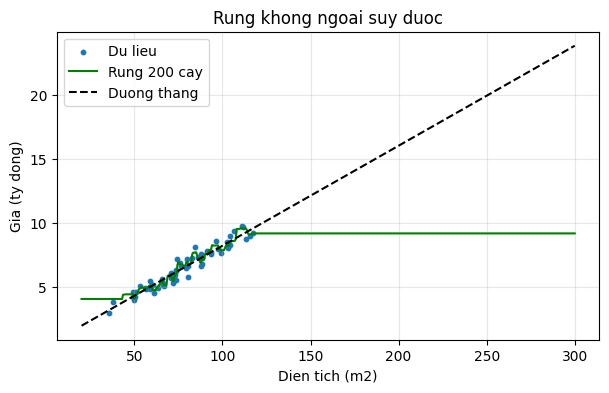

In [17]:
from sklearn.ensemble import RandomForestRegressor

rf = RandomForestRegressor(n_estimators=200, random_state=0).fit(Xn_tr, yn_tr)
mae_rf = mean_absolute_error(yn_te, rf.predict(Xn_te))
print("MAE tren tap kiem tra (ty dong)")
print(f"  Rung 200 cay: {mae_rf:.4f}")
print(f"  Cay sau 3   : {mae_cay:.4f}")
print(f"  Duong thang : {mae_duong:.4f}\n")

can_250 = pd.DataFrame({"dien_tich": [250.0]})
print(f"Rung doan can 250 m2: {rf.predict(can_250)[0]:.2f} ty")
print(f"Cay sau 3 doan       : {cay_hq.predict(can_250)[0]:.2f} ty")
print(f"Duong thang doan     : {duong.predict(can_250)[0]:.2f} ty")

# Moi cay trong rung cho du doan gi cho can 250 m2?
tung_cay = np.array([c.predict(can_250.to_numpy())[0] for c in rf.estimators_])
print(f"\nDu doan cua 200 cay: nho nhat {tung_cay.min():.2f}, lon nhat {tung_cay.max():.2f}")
print(f"Gia lon nhat trong tap hoc: {yn_tr.max():.2f} ty (dien tich lon nhat {Xn_tr['dien_tich'].max():.1f} m2)")

xs = pd.DataFrame({"dien_tich": np.linspace(20, 300, 500)})
plt.figure(figsize=(7, 4))
plt.scatter(Xn["dien_tich"], yn, s=10, label="Du lieu")
plt.plot(xs["dien_tich"], rf.predict(xs), color="green", label="Rung 200 cay")
plt.plot(xs["dien_tich"], duong.predict(xs), "k--", label="Duong thang")
plt.xlabel("Dien tich (m2)"); plt.ylabel("Gia (ty dong)"); plt.legend(); plt.grid(alpha=.3)
plt.title("Rung khong ngoai suy duoc"); plt.show()

**Giải thích Bài 6:** MAE của rừng là 0.4559, tốt hơn cây sâu 3 (0.5039) nhưng vẫn kém đường thẳng (0.2578), vì giá nhà tăng gần như thẳng theo diện tích. Căn 250 m² được rừng đoán **9.20 tỷ**
(đường thẳng đoán 19.91 tỷ), nên rừng **không ngoại suy được**. Với căn 250 m² (lớn hơn mọi căn trong tập học, căn lớn nhất 117.5 m²), mỗi cây đều rơi vào một lá ngoài cùng bên phải, và lá chỉ trả về
trung bình giá của các căn đã thấy trong lá đó. Dự đoán của 200 cây nằm trong khoảng 8.52 đến 9.74 tỷ (giá cao nhất của tập học là 9.74), và rừng lấy trung bình của chúng nên kết quả
không bao giờ vượt khỏi khoảng giá đã thấy. Rừng mượt hơn cây đơn (bậc thang mịn hơn), nhưng vẫn là "nói lại những gì đã thấy".